In [1]:
import numpy as np

def wind_eq(tau, y, gamma, xc):

    x, v = y

    if x < xc:
        gamma_local = 0.0
    else:
        gamma_local = gamma

    dxdtau = (np.pi / 2) * v

    dvdtau = -(np.pi / 4) * (1 - gamma_local) / x**2

    return [dxdtau, dvdtau]

In [2]:
y0 = [1.0, 0.8]

In [3]:
#figure 1

gamma = 5.0
xc = 2.5

In [4]:
#25 free-fall times

tau_span = (0.0, 25.0)

In [5]:
from scipy.integrate import solve_ivp

solution = solve_ivp(
    wind_eq,
    tau_span,
    y0,
    args=(gamma, xc),
    method="DOP853"
)

In [6]:
#dimensionless times

solution.t

array([ 0.        ,  0.21853019,  0.94021282,  2.11428244,  2.25594891,
        2.30865983,  2.36137075,  2.40932026,  2.8888154 ,  5.04306689,
        7.69801334, 14.28332267, 24.45740705, 25.        ])

In [7]:
# x=r/R*

solution.y[0]

array([ 1.        ,  1.2494653 ,  1.84908849,  2.43280332,  2.48101659,
        2.49792055,  2.51549321,  2.53336122,  2.80432299,  5.3644449 ,
        9.71574667, 21.82958596, 41.46762973, 42.52726689])

In [8]:
#ups=u/u_esc

solution.y[1]

array([0.8       , 0.66358296, 0.42521227, 0.22593514, 0.20750623,
       0.20082639, 0.2253831 , 0.24902405, 0.46322105, 0.94620231,
       1.10871372, 1.20735874, 1.24277606, 1.24374266])

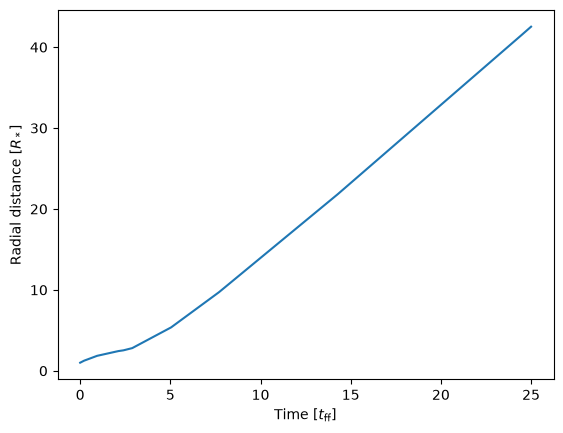

In [9]:
import matplotlib.pyplot as plt

plt.plot(solution.t, solution.y[0])

plt.xlabel(r"Time [$t_{\rm ff}$]")
plt.ylabel(r"Radial distance [$R_*$]")


plt.savefig("Rt.png", dpi=300)
plt.show()

In [10]:
tau_eval = np.linspace(0, 25, 1000)

solution = solve_ivp(
    wind_eq,
    (0, 25),
    y0,
    args=(gamma, xc),
    method="DOP853",
    t_eval=tau_eval
)

In [11]:
gammas = [5.0, 1.0, 0.0]
xc = 2.5

tau_eval = np.linspace(0, 25, 1000)

solutions = []

for gamma in gammas:

    sol = solve_ivp(
        wind_eq,
        (0, 25),
        y0,
        args=(gamma, xc),
        method="DOP853",
        t_eval=tau_eval
    )

    solutions.append(sol)

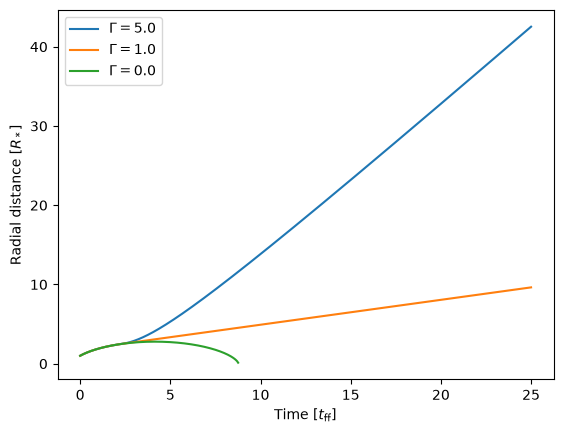

In [12]:
for sol, gamma in zip(solutions, gammas):
    plt.plot(sol.t, sol.y[0], label=fr"$\Gamma={gamma}$")

plt.xlabel(r"Time [$t_{\rm ff}$]")
plt.ylabel(r"Radial distance [$R_*$]")

plt.legend()

plt.savefig("gammas.png", dpi=300)
plt.show()

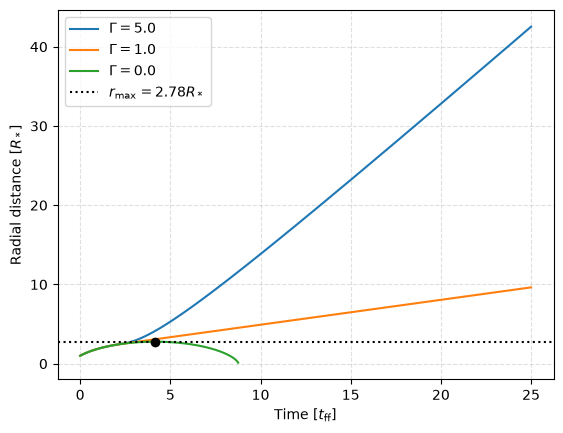

In [13]:
# Find the Gamma = 0 solution
sol_gamma0 = solutions[2]

# Find index where radial distance is maximum
imax = np.argmax(sol_gamma0.y[0])

# Time and radius at maximum distance
tau_rmax = sol_gamma0.t[imax]
rmax = sol_gamma0.y[0][imax]

# Plot the three trajectories
for sol, gamma in zip(solutions, gammas):
    plt.plot(sol.t, sol.y[0], label=fr"$\Gamma={gamma}$")

# Vertical dotted line at the time when r_max is reached
plt.axhline(
    rmax,
    color="black",
    linestyle=":",
    linewidth=1.5,
    label=fr"$r_{{\max}}={rmax:.2f}R_*$"
)

# Mark the actual r_max point
plt.scatter(tau_rmax, rmax, color="black", zorder=5)

# Grid
plt.grid(True, linestyle="--", alpha=0.4)

plt.xlabel(r"Time [$t_{\rm ff}$]")
plt.ylabel(r"Radial distance [$R_*$]")
plt.legend()


plt.savefig("gammas.png", dpi=300)
plt.show()

In [14]:
#second code test
gamma = 5.0
xcs = [2.0, 2.5, 3.0]

tau_eval = np.linspace(0, 25, 1000)

solutions_rc = []

for xc in xcs:

    sol = solve_ivp(
        wind_eq,
        (0, 25),
        y0,
        args=(gamma, xc),
        method="DOP853",
        t_eval=tau_eval
    )

    solutions_rc.append(sol)

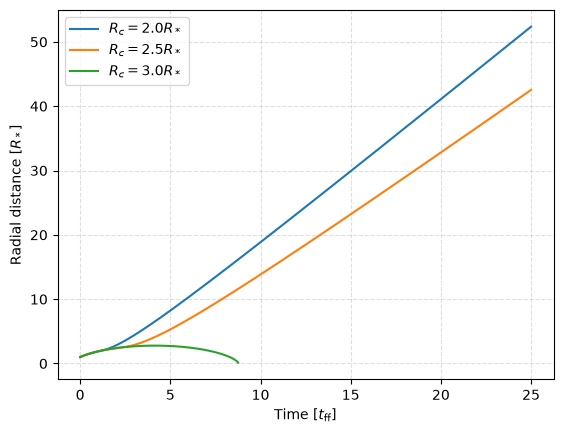

In [15]:
for sol, xc in zip(solutions_rc, xcs):
    plt.plot(
        sol.t,
        sol.y[0],
        label=fr"$R_c={xc}R_*$"
    )

plt.xlabel(r"Time [$t_{\rm ff}$]")
plt.ylabel(r"Radial distance [$R_*$]")

plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()


plt.savefig("radiuses.png", dpi=300)
plt.show()

In [16]:
# constants
G = 6.67430e-11
c = 2.99792458e8
M_sun = 1.98847e30
L_sun = 3.828e26

# Stellar parameters
M_star = 1.5 * M_sun
L_star = 7000 * L_sun
T_star = 2600.0

# Amorphous carbon properties
T_c = 1500.0
p = 1.0
Qrp_over_a = 2.0e6
A_mon = 12.0
rho_grain = 1.85e3
epsilon_c = 3.3e-4
epsilon_He = 0.1
f_c = 0.2

# Condensation radius in units of R_star
xc = 0.5 * (T_c / T_star)**(-(4 + p) / 2)

# Dust opacity
kappa_H = (
    (3/4)
    * (A_mon / rho_grain)
    * Qrp_over_a
    * (epsilon_c / (1 + 4*epsilon_He))
    * f_c
)

# Gamma
gamma = kappa_H * L_star / (4*np.pi*c*G*M_star)

print("Rc/R* =", xc)
print("kappa_H =", kappa_H, "m^2/kg")
print("Gamma =", gamma)

Rc/R* = 1.9777674573180588
kappa_H = 0.4586872586872588 m^2/kg
Gamma = 1.6388531976650218


In [17]:
def wind_eq( tau, y, gamma, xc):
    x, v =y
    if x < xc:
        gamma_local=0.0
    else:
        gamma_local = gamma
        dxdtau = (np.pi/2)*v
        dvdtau = -(np.pi/4)*(1-gamma_local/x**2)

        return[dxdtau, dvdtau]

In [18]:


def before_dust(tau, y):
    x, v = y

    dxdtau = (np.pi / 2) * v
    dvdtau = -(np.pi / 4) / x**2

    return [dxdtau, dvdtau]


# Stop when x reaches xc
def reach_xc(tau, y):
    return y[0] - xc

reach_xc.terminal = True
reach_xc.direction = 1


sol1 = solve_ivp(
    before_dust,
    (0, 25),
    y0,
    method="DOP853",
    events=reach_xc
)

print(sol1.success)
print("Reached Rc at tau =", sol1.t_events[0])

True
Reached Rc at tau = [1.14352921]


In [19]:
# after dust formation

def after_dust(tau, y):
    x, v = y

    dxdtau = (np.pi / 2) * v
    dvdtau = -(np.pi / 4) * (1 - gamma) / x**2

    return [dxdtau, dvdtau]


# Time and state when the parcel reaches Rc
tau_c = sol1.t_events[0][0]
y_c = sol1.y_events[0][0]

print("tau_c =", tau_c)
print("x_c =", y_c[0])
print("v_c =", y_c[1])


# Integrate from Rc to 25 free-fall times
tau_eval2 = np.linspace(tau_c, 25, 1000)

sol2 = solve_ivp(
    after_dust,
    (tau_c, 25),
    y_c,
    method="DOP853",
    t_eval=tau_eval2
)

print("Stage 2 successful:", sol2.success)

tau_c = 1.1435292095355485
x_c = 1.9777674573180588
v_c = 0.3816005620004213
Stage 2 successful: True


In [20]:
#total trajectory 

tau_all = np.concatenate((sol1.t, sol2.t))
x_all = np.concatenate((sol1.y[0], sol2.y[0]))
v_all = np.concatenate((sol1.y[1], sol2.y[1]))

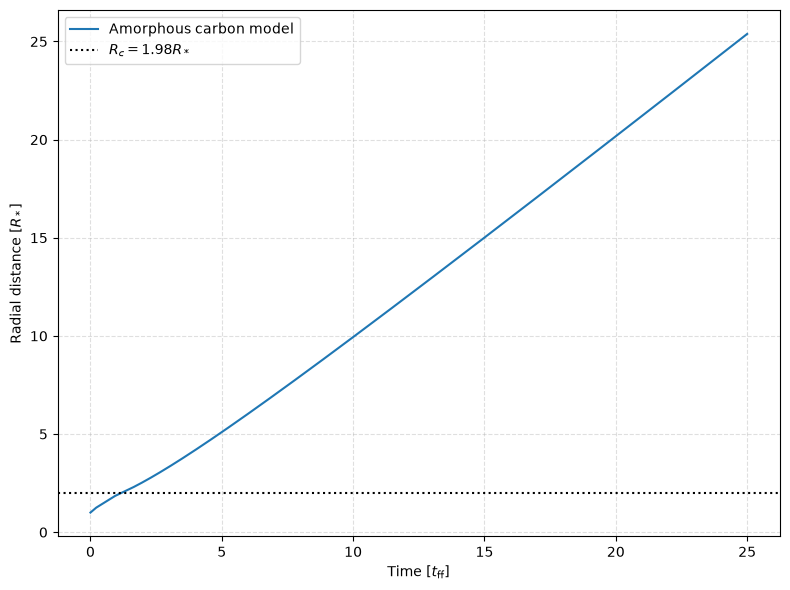

In [21]:
#trajectory plot

plt.figure(figsize=(8, 6))

plt.plot(
    tau_all,
    x_all,
    label="Amorphous carbon model"
)

plt.axhline(
    xc,
    color="black",
    linestyle=":",
    label=fr"$R_c={xc:.2f}R_*$"
)

plt.xlabel(r"Time [$t_{\rm ff}$]")
plt.ylabel(r"Radial distance [$R_*$]")

plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()


plt.savefig("amorph.png", dpi=300)
plt.show()

In [22]:
#convert dimensionless velocity

sigma = 5.670374419e-8

R_star = np.sqrt(
    L_star / (4 * np.pi * sigma * T_star**4)
)

u_esc = np.sqrt(
    2 * G * M_star / R_star
)

print("R_star =", R_star, "m")
print("u_esc =", u_esc / 1000, "km/s")

R_star = 286864950118.4807 m
u_esc = 37.254974170648076 km/s


In [23]:
#m/s to km/s

u_all = v_all * u_esc / 1000

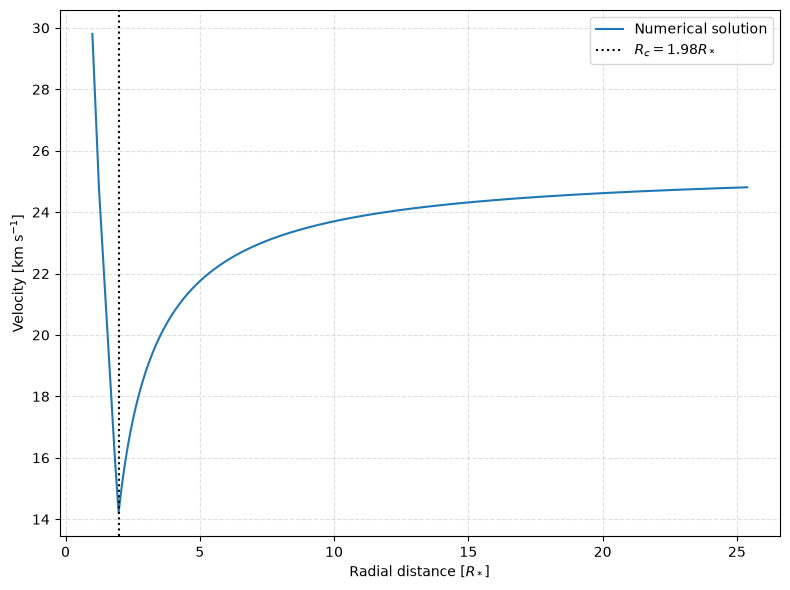

In [24]:
#v-R

plt.figure(figsize=(8, 6))

plt.plot(
    x_all,
    u_all,
    label="Numerical solution"
)

plt.axvline(
    xc,
    color="black",
    linestyle=":",
    label=fr"$R_c={xc:.2f}R_*$"
)

plt.xlabel(r"Radial distance [$R_*$]")
plt.ylabel(r"Velocity [km s$^{-1}$]")

plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()


plt.savefig("velrad.png", dpi=300)
plt.show()

In [25]:
v_c = sol1.y[1, -1]
u_c = v_c * u_esc

print("v_c =", v_c)
print("Velocity at Rc =", u_c / 1000, "km/s")

v_c = 0.3816005620004213
Velocity at Rc = 14.216519080830487 km/s


In [26]:
#analytical solution

r_analytic = sol2.y[0] * R_star

u_analytic = np.sqrt(
    u_c**2
    + 2 * G * M_star * (1 - gamma)
    * (1 / r_analytic - 1 / (xc * R_star))
)

u_analytic_kms = u_analytic / 1000

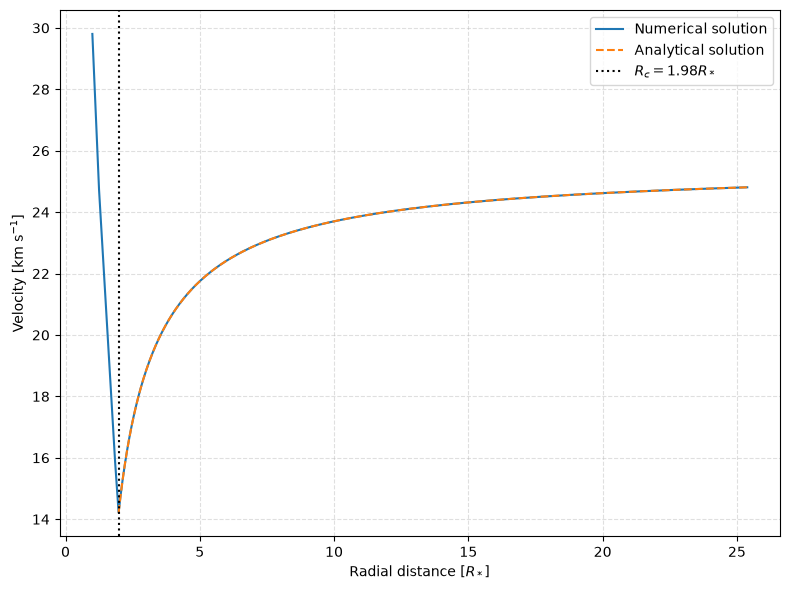

In [27]:
# plot numer and analytical together

plt.figure(figsize=(8, 6))

# Numerical solution
plt.plot(
    x_all,
    u_all,
    label="Numerical solution"
)

# Analytical solution in dusty region
plt.plot(
    sol2.y[0],
    u_analytic_kms,
    "--",
    label="Analytical solution"
)

plt.axvline(
    xc,
    color="black",
    linestyle=":",
    label=fr"$R_c={xc:.2f}R_*$"
)

plt.xlabel(r"Radial distance [$R_*$]")
plt.ylabel(r"Velocity [km s$^{-1}$]")

plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()


plt.savefig("numanal.png", dpi=300)
plt.show()

In [28]:
# terminal velocity

u_inf = np.sqrt(
    u_c**2
    + 2 * G * M_star * (gamma - 1)
    / (xc * R_star)
)

print("Terminal velocity =", u_inf / 1000, "km/s")
print("Numerical velocity at final radius =", u_all[-1], "km/s")

Terminal velocity = 25.50364450687052 km/s
Numerical velocity at final radius = 24.80942022945855 km/s


In [29]:
#radius to astronomical units

AU = 1.495978707e11

r_AU = x_all * R_star / AU
Rc_AU = xc * R_star / AU

print("Stellar radius =", R_star / AU, "AU")
print("Condensation radius =", Rc_AU, "AU")

Stellar radius = 1.9175737513921762 AU
Condensation radius = 3.7925149625107557 AU


In [32]:
#local escape v

r_m = x_all * R_star

u_esc_local = np.sqrt(
    2 * G * M_star / r_m
) / 1000

print(u_esc, "km/s")

37254.97417064808 km/s


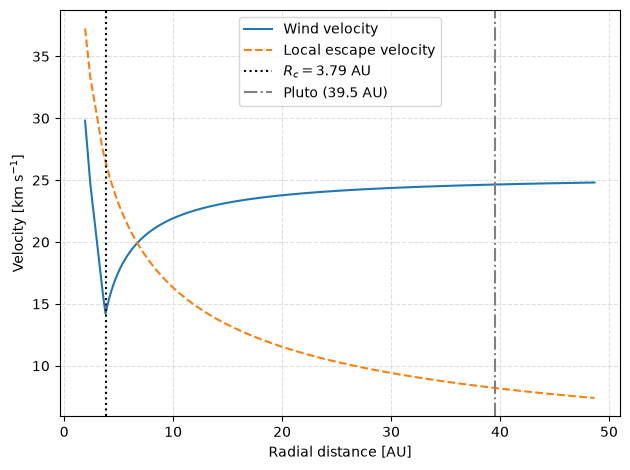

In [51]:
#physical distance plot plt.figure(figsize=(8, 6))

plt.plot(
    r_AU,
    u_all,
    label="Wind velocity"
)

plt.plot(
    r_AU,
    u_esc_local,
    "--",
    label = "Local escape velocity"
)

plt.axvline(
    Rc_AU,
    color="black",
    linestyle=":",
    label=fr"$R_c={Rc_AU:.2f}$ AU"
)

plt.axvline(
    39.5,
    color="gray",
    linestyle="-.",
    label="Pluto (39.5 AU)"
)

plt.xlabel("Radial distance [AU]")
plt.ylabel(r"Velocity [km s$^{-1}$]")

plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()


plt.savefig("velocities.png", dpi=300)
plt.show()

In [49]:
difference = u_all - u_esc_local

indices = np.where(difference > 0)[0]

i_escape = indices[0]

print("Wind exceeds local escape velocity at:")
print("r/R* =", x_all[i_escape])
print("r =", r_AU[i_escape], "AU")
print("u =", u_all[i_escape], "km/s")
print("u_esc =", u_esc_local[i_escape], "km/s")

Wind exceeds local escape velocity at:
r/R* = 3.5030811081559055
r = 6.717416381997581 AU
u = 19.932800024738967 km/s
u_esc = 19.904861965491094 km/s


In [50]:
r_pluto_AU = 39.5
r_pluto = r_pluto_AU * AU

u_pluto = np.sqrt(
    u_c**2
    + 2 * G * M_star * (1 - gamma)
    * (1 / r_pluto - 1 / (xc * R_star))
)

u_pluto = u_pluto / 1000

print("Velocity at Pluto distance =", u_pluto, "km/s")
print("Terminal velocity =", u_inf / 1000, "km/s")
print(
    "Fraction of terminal velocity =",
    u_pluto / (u_inf / 1000)
)

Velocity at Pluto distance = 24.645297671703922 km/s
Terminal velocity = 25.50364450687052 km/s
Fraction of terminal velocity = 0.9663441499533385
